# Lista 3 – Exercício 1 (Paula, Cap. 3, Ex. 20): custo médio de sinistros

**Enunciado (resumo).** Amostra de 996 apólices de seguro de veículos (de Jong e Heller, 2008).
Resposta: `cmsinistros = csinistros / nsinistros` (custo médio por sinistro).

1. Análise descritiva e **agrupamento de categorias** das variáveis qualitativas;
2. Ajuste de modelos **gama** e **normal inversa** com $\phi$ constante;
3. Análise de diagnóstico;
4. Interpretação dos coeficientes do modelo final.

(Pela OBS1 da lista, não ajustamos modelos duplos.)

## 1. Pacotes e dados

In [1]:
# Caminho relativo: o notebook e o claims.csv estão na mesma pasta ("Lista 3/"),
# então não é preciso escrever o caminho completo do computador.
claims <- read.csv("claims.csv")
claims$cmsinistros <- claims$csin / claims$nsin   # resposta

# Variáveis qualitativas como fator (idadev e idadec vêm como números 1..6)
for (v in c("tipov", "idadev", "genero", "areac", "idadec"))
  claims[[v]] <- factor(claims[[v]])

str(claims)

'data.frame':	996 obs. of  11 variables:
 $ valorv     : num  1.66 1.51 0.76 1.89 4.06 1.39 2.66 0.5 1.16 3.56 ...
 $ expos      : num  0.485 0.994 0.539 0.654 0.851 ...
 $ nsin       : int  1 1 1 2 1 1 1 1 2 1 ...
 $ csin       : num  670 807 402 1812 5434 ...
 $ tipov      : Factor w/ 11 levels "BUS","COUPE",..: 8 8 3 9 9 3 9 3 9 5 ...
 $ idadev     : Factor w/ 4 levels "1","2","3","4": 3 3 3 3 2 3 1 4 4 3 ...
 $ genero     : Factor w/ 2 levels "F","M": 2 1 2 2 2 1 1 1 1 2 ...
 $ areac      : Factor w/ 6 levels "A","B","C","D",..: 2 6 3 6 6 1 6 1 2 6 ...
 $ idadec     : Factor w/ 6 levels "1","2","3","4",..: 6 4 4 2 3 4 5 5 2 4 ...
 $ cmsinistros: num  670 807 402 906 5434 ...
 $ tipo_grp   : chr  "SEDAN" "SEDAN" "HBACK" "STNWG" ...


## 2. Análise descritiva

### 2.1 Variável resposta

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  200.0   353.8   643.6  1731.3  1787.6 26507.3 

Coef. de variação: 1.71 


Obs. com cmsinistros = 200 exatamente: 163 


nsin
  1   2   3   4 
941  50   4   1 

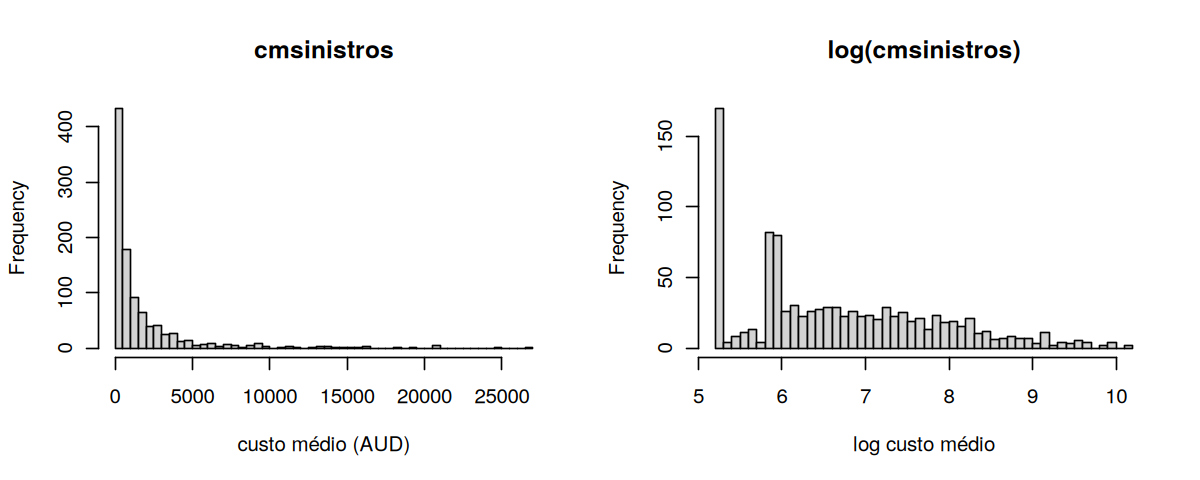

In [2]:
options(repr.plot.width = 10, repr.plot.height = 4)
par(mfrow = c(1, 2))
hist(claims$cmsinistros, breaks = 40, main = "cmsinistros", xlab = "custo médio (AUD)")
hist(log(claims$cmsinistros), breaks = 40, main = "log(cmsinistros)", xlab = "log custo médio")
par(mfrow = c(1, 1))

summary(claims$cmsinistros)
cat("Coef. de variação:", round(sd(claims$cmsinistros) / mean(claims$cmsinistros), 2), "\n")
cat("Obs. com cmsinistros = 200 exatamente:", sum(claims$cmsinistros == 200), "\n")
table(nsin = claims$nsin)

**Comentário.** A resposta é fortemente assimétrica à direita (média 1731 contra mediana 644, CV = 1,71), então faz sentido usar distribuições para resposta positiva e assimétrica (gama e normal inversa). Na escala log a distribuição fica bem mais simétrica, o que indica a ligação log.

⚠️ **Detalhe importante:** **163 apólices (16%) têm custo médio igual a 200, exatamente**. É um piso do banco, e há também acúmulos em torno de 354 e 390. Um ponto com tanta massa não é reproduzido por nenhuma distribuição contínua, e isso vai aparecer no diagnóstico. Além disso, 94% das apólices têm só 1 sinistro.

### 2.2 Covariáveis contínuas

     valorv          expos         
 Min.   :0.000   Min.   :0.005476  
 1st Qu.:1.130   1st Qu.:0.443532  
 Median :1.600   Median :0.616016  
 Mean   :1.859   Mean   :0.614804  
 3rd Qu.:2.350   3rd Qu.:0.848734  
 Max.   :7.199   Max.   :0.999316  

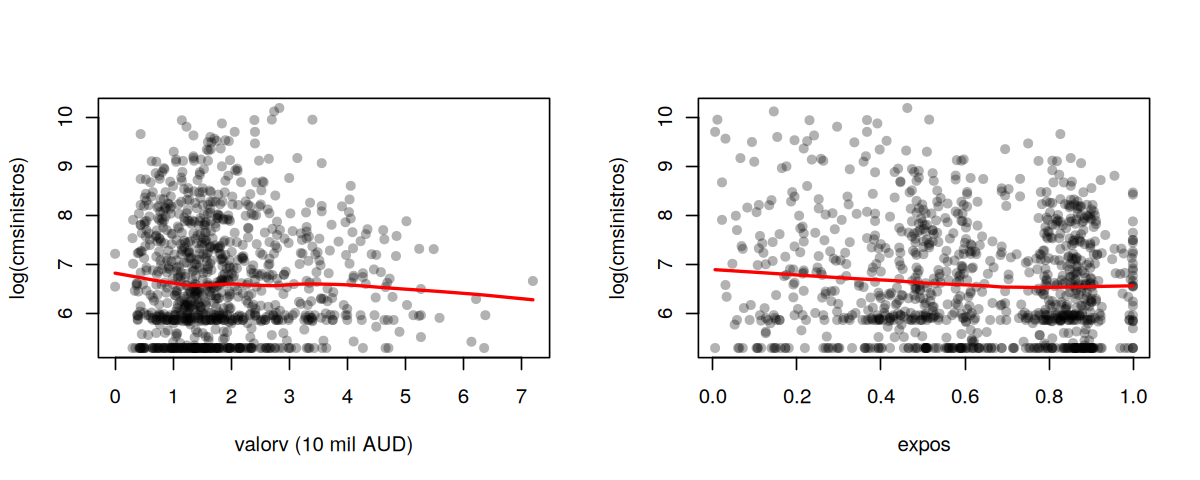

In [3]:
summary(claims[, c("valorv", "expos")])

par(mfrow = c(1, 2))
plot(claims$valorv, log(claims$cmsinistros), pch = 16, col = rgb(0, 0, 0, .3),
     xlab = "valorv (10 mil AUD)", ylab = "log(cmsinistros)")
lines(lowess(claims$valorv, log(claims$cmsinistros)), col = "red", lwd = 2)
plot(claims$expos, log(claims$cmsinistros), pch = 16, col = rgb(0, 0, 0, .3),
     xlab = "expos", ylab = "log(cmsinistros)")
lines(lowess(claims$expos, log(claims$cmsinistros)), col = "red", lwd = 2)
par(mfrow = c(1, 1))

**Comentário.** `valorv` não mostra relação clara com o log do custo (lowess quase plano), e há 2 apólices com `valorv = 0`, o que provavelmente indica valor faltante. `expos` mostra uma leve tendência decrescente.

### 2.3 Covariáveis qualitativas

In [4]:
# Uma função só para todas as qualitativas (sem precisar do doBy).
# Média na escala log, porque é nessa escala que o modelo (ligação log) trabalha.
resumo <- function(v) {
  y <- claims$cmsinistros; g <- claims[[v]]
  data.frame(n = tapply(y, g, length),
             media = round(tapply(y, g, mean)),
             media_log = round(tapply(log(y), g, mean), 3),
             dp_log = round(tapply(log(y), g, sd), 3))
}
for (v in c("tipov", "idadev", "genero", "areac", "idadec")) {
  cat("\n====", v, "====\n"); print(resumo(v))
}


==== tipov ====
        n media media_log dp_log
BUS     1  2621     7.871     NA
COUPE  11  1650     6.965  1.076
HBACK 272  1752     6.642  1.211
HDTOP  23  2134     6.742  1.261
MCARA   4  1285     6.727  1.070
MIBUS   6  3009     7.003  1.450
PANVN  11  3018     7.258  1.298
SEDAN 314  1502     6.639  1.102
STNWG 268  1724     6.703  1.086
TRUCK  28  3083     7.080  1.337
UTE    58  1755     6.822  1.116

==== idadev ====
    n media media_log dp_log
1 187  1435     6.601  1.031
2 264  1701     6.617  1.165
3 309  1785     6.746  1.150
4 236  1930     6.798  1.191

==== genero ====
    n media media_log dp_log
F 567  1643     6.676  1.129
M 429  1848     6.725  1.164

==== areac ====
    n media media_log dp_log
A 233  1552     6.620  1.141
B 196  1529     6.669  1.083
C 313  1723     6.647  1.173
D 108  1669     6.717  1.086
E  90  2508     6.963  1.227
F  56  2103     6.927  1.129

==== idadec ====
    n media media_log dp_log
1 110  2270     6.827  1.310
2 207  2038     6.750  

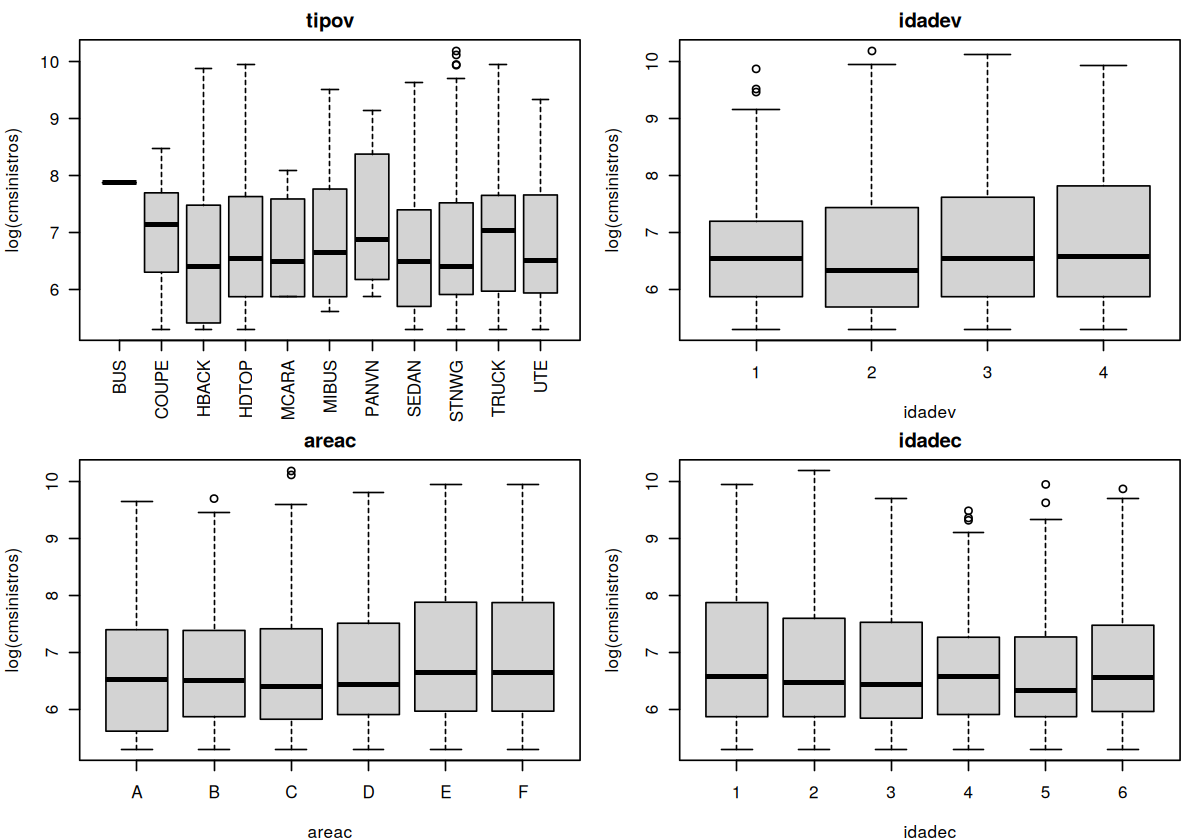

In [5]:
options(repr.plot.width = 10, repr.plot.height = 7)
par(mfrow = c(2, 2), mar = c(4, 4, 2, 1))
boxplot(log(cmsinistros) ~ tipov,  data = claims, las = 2, xlab = "", main = "tipov")
boxplot(log(cmsinistros) ~ idadev, data = claims, main = "idadev")
boxplot(log(cmsinistros) ~ areac,  data = claims, main = "areac")
boxplot(log(cmsinistros) ~ idadec, data = claims, main = "idadec")
par(mfrow = c(1, 1))

**Comentário (guia para o agrupamento).**
- `tipov`: há 11 categorias, várias com pouquíssimas observações (BUS = 1, MCARA = 4, MIBUS = 6), e isso explica os erros-padrão de ~1,5 no modelo com as categorias originais. HBACK, SEDAN, STNWG, HDTOP e MCARA têm média do log parecida (6,64–6,74). As demais (COUPE, MIBUS, PANVN, TRUCK, UTE, BUS) ficam acima.
- `idadev`: as classes 1 e 2 são parecidas entre si, e as classes 3 e 4 também.
- `genero`: a diferença é pequena.
- `areac`: A–D ficam entre 6,62 e 6,72, e E–F são claramente maiores (~6,95).
- `idadec`: forma de **U**: os condutores jovens (1–2) e os mais velhos (6) têm custo maior que os intermediários (3–5).

## 3. Agrupamento de categorias

In [6]:
claims$tipov2 <- factor(ifelse(claims$tipov %in% c("HBACK", "SEDAN", "STNWG", "HDTOP", "MCARA"),
                               "comum", "outros"), levels = c("comum", "outros"))
claims$idadev2 <- factor(ifelse(claims$idadev %in% c("1", "2"), "1-2", "3-4"))
claims$areac2  <- factor(ifelse(claims$areac %in% c("E", "F"), "EF", "A-D"), levels = c("A-D", "EF"))
claims$idadec2 <- factor(ifelse(claims$idadec %in% c("1", "2"), "1-2",
                         ifelse(claims$idadec == "6", "6", "3-5")), levels = c("3-5", "1-2", "6"))

for (v in c("tipov2", "idadev2", "areac2", "idadec2")) {
  cat("\n====", v, "====\n"); print(resumo(v))
}


==== tipov2 ====
         n media media_log dp_log
comum  881  1662     6.663  1.134
outros 115  2262     6.959  1.191

==== idadev2 ====
      n media media_log dp_log
1-2 451  1591     6.611  1.110
3-4 545  1848     6.768  1.167

==== areac2 ====
      n media media_log dp_log
A-D 850  1625     6.654  1.132
EF  146  2353     6.949  1.187

==== idadec2 ====
      n media media_log dp_log
3-5 592  1452     6.631  1.067
1-2 317  2119     6.776  1.253
6    87  2218     6.857  1.212


Os agrupamentos seguem as tabelas acima. Em cada variável, a referência é o grupo maior (`comum`, `1-2`, `A-D`, `3-5`), o que deixa as estimativas mais estáveis e a interpretação mais natural.

In [7]:
# Modelo gama com as categorias originais x agrupadas (modelos encaixados).
# Teste F porque phi é desconhecido (estimado).
aj0 <- glm(cmsinistros ~ valorv + expos + tipov + idadev + genero + areac + idadec,
           family = Gamma(link = "log"), data = claims)
aj1 <- glm(cmsinistros ~ valorv + expos + tipov2 + idadev2 + genero + areac2 + idadec2,
           family = Gamma(link = "log"), data = claims)
anova(aj1, aj0, test = "F")

,Resid. Df,Resid. Dev,Df,Deviance,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,987,1366.180,NA,NA,NA,NA
2,969,1352.251,18,13.92915,0.3605504,0.9935789


**Comentário.** p-valor = 0,99: o modelo agrupado (8 parâmetros) não perde ajuste em relação ao original (26 parâmetros), então os agrupamentos são aceitáveis.

## 4. Seleção de variáveis – modelo gama (ligação log)

Backward com teste F: retiramos **uma variável por vez** (a de maior p-valor) e reajustamos, porque o p-valor das outras muda a cada retirada.

In [8]:
drop1(aj1, test = "F")

,Df,Deviance,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,1366.180,16718.82,NA,NA
valorv,1,1368.517,16717.90,1.6881555,1.941477e-01
expos,1,1433.678,16748.07,48.7643452,5.296745e-12
tipov2,1,1375.747,16721.25,6.9114353,8.697738e-03
idadev2,1,1368.713,16717.99,1.8297455,1.764674e-01
genero,1,1367.439,16717.41,0.9099419,3.403634e-01
areac2,1,1382.242,16724.26,11.6042310,6.845594e-04
idadec2,2,1392.367,16726.95,9.4593946,8.525379e-05


In [9]:
aj2 <- update(aj1, . ~ . - genero)   # maior p-valor
drop1(aj2, test = "F")

,Df,Deviance,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,1367.439,16717.93,NA,NA
valorv,1,1369.238,16716.76,1.299162,2.546426e-01
expos,1,1435.253,16747.41,48.996464,4.729101e-12
tipov2,1,1378.370,16721.00,7.897658,5.047663e-03
idadev2,1,1370.332,16717.27,2.090107,1.485728e-01
areac2,1,1384.119,16723.67,12.050950,5.400614e-04
idadec2,2,1393.530,16726.04,9.425501,8.812897e-05


In [10]:
aj3 <- update(aj2, . ~ . - valorv)   # maior p-valor agora
drop1(aj3, test = "F")

,Df,Deviance,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,1369.238,16717.50,NA,NA
expos,1,1438.089,16747.60,49.731185,3.308270e-12
tipov2,1,1379.364,16720.22,7.314353,6.958084e-03
idadev2,1,1376.809,16719.03,5.468650,1.955902e-02
areac2,1,1384.261,16722.50,10.851307,1.022287e-03
idadec2,2,1396.607,16726.26,9.884638,5.616916e-05


**Comentário.** Primeiro sai `genero` (p = 0,34) e depois `valorv` (p = 0,25). Com `valorv` fora, `idadev2` **passa a ser significativa** (p = 0,02). Esse é o motivo de retirar uma variável por vez e não todas as não significativas de uma vez só. Modelo final: `expos + tipov2 + idadev2 + areac2 + idadec2`.

In [11]:
# Teste conjunto: o modelo final x o modelo agrupado completo
anova(aj3, aj1, test = "F")
summary(aj3)

,Resid. Df,Resid. Dev,Df,Deviance,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,989,1369.238,NA,NA,NA,NA
2,987,1366.180,2,3.057621,0.7077853,0.4929842



Call:
glm(formula = cmsinistros ~ expos + tipov2 + idadev2 + areac2 + 
    idadec2, family = Gamma(link = "log"), data = claims)

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)   7.68940    0.14214  54.096  < 2e-16 ***
expos        -1.01057    0.18324  -5.515 4.45e-08 ***
tipov2outros  0.30518    0.14682   2.079  0.03790 *  
idadev23-4    0.17677    0.09354   1.890  0.05908 .  
areac2EF      0.33446    0.13180   2.538  0.01131 *  
idadec21-2    0.31052    0.10268   3.024  0.00256 ** 
idadec26      0.41610    0.16903   2.462  0.01400 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for Gamma family taken to be 2.144527)

    Null deviance: 1513.4  on 995  degrees of freedom
Residual deviance: 1369.2  on 989  degrees of freedom
AIC: 16717

Number of Fisher Scoring iterations: 7


## 5. Diagnóstico – gama

In [12]:
# Função de diagnóstico reaproveitada para os dois modelos.
# Resíduo quantílico (Dunn & Smyth): r_q = qnorm(F(y; mu, phi)); deve ser ~N(0,1) se o modelo for adequado.
res_quantilico <- function(fit) {
  # phi pela máxima verossimilhança (é o que o gamlss usa). O phi de Pearson do summary()
  # é bem maior aqui (2,14 contra 1,17 na gama) por causa da cauda pesada e deixaria r_q "estreito".
  y <- fit$y; mu <- fitted(fit)
  phi <- if (fit$family$family == "Gamma") MASS::gamma.dispersion(fit) else deviance(fit) / length(y)
  if (fit$family$family == "Gamma") {
    u <- pgamma(y, shape = 1 / phi, scale = mu * phi)
  } else {                                   # normal inversa, lambda = 1/phi
    lam <- 1 / phi
    u <- pnorm(sqrt(lam / y) * (y / mu - 1)) +
         exp(2 * lam / mu) * pnorm(-sqrt(lam / y) * (y / mu + 1))
  }
  qnorm(u)
}

diagnostico <- function(fit, titulo = "") {
  n <- length(fit$y); p <- length(coef(fit))
  h  <- hatvalues(fit)
  td <- rstandard(fit, type = "deviance")
  ci <- cooks.distance(fit)
  rq <- res_quantilico(fit)
  par(mfrow = c(2, 3), mar = c(4, 4, 2, 1), oma = c(0, 0, 2, 0))
  plot(h, pch = 16, cex = .6, ylab = "h_ii", main = "Alavancagem"); abline(h = 2 * p / n, lty = 2, col = "red")
  plot(ci, pch = 16, cex = .6, ylab = "Distância de Cook", main = "Influência")
  plot(td, pch = 16, cex = .6, ylab = "t_D", main = "Resíduo desvio padronizado"); abline(h = c(-2, 2), lty = 2, col = "red")
  plot(fitted(fit), td, pch = 16, cex = .6, log = "x", xlab = "valor ajustado (escala log)", ylab = "t_D",
       main = "t_D x ajustado"); abline(h = c(-2, 2), lty = 2, col = "red")
  qqnorm(rq, pch = 16, cex = .6, main = "QQ – resíduo quantílico"); qqline(rq, col = "red")
  hist(rq, breaks = 40, main = "Resíduo quantílico", xlab = "r_q")
  mtext(titulo, outer = TRUE, font = 2, cex = 1.2); par(mfrow = c(1, 1), oma = c(0, 0, 0, 0))
  cat("Pontos com h > 2p/n:", sum(h > 2 * p / n), "| |t_D| > 2:", sum(abs(td) > 2),
      "(", round(100 * mean(abs(td) > 2), 1), "%)\n")
  cat("Maiores Cook:\n"); print(round(sort(ci, decreasing = TRUE)[1:5], 4))
  cat("Resíduo quantílico: média =", round(mean(rq), 3), " dp =", round(sd(rq), 3),
      " assimetria =", round(mean((rq - mean(rq))^3) / sd(rq)^3, 3), "\n")
  invisible(list(h = h, td = td, ci = ci, rq = rq))
}

Pontos com h > 2p/n: 52 | |t_D| > 2: 9 ( 0.9 %)
Maiores Cook:
   694    580    789    350     32 
0.0593 0.0439 0.0385 0.0313 0.0312 
Resíduo quantílico: média = -0.035  dp = 0.982  assimetria = 1.182 


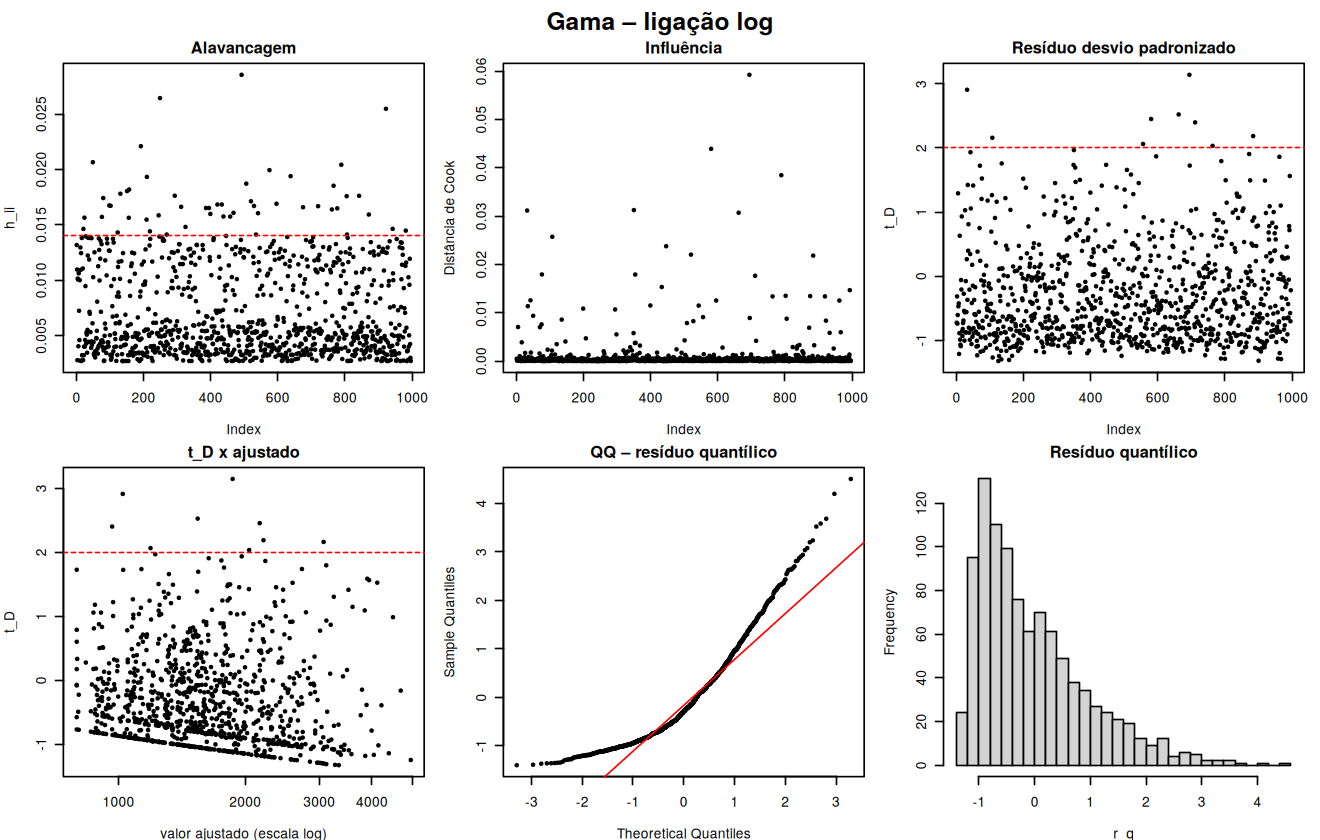

In [13]:
options(repr.plot.width = 11, repr.plot.height = 7)
dg <- diagnostico(aj3, "Gama – ligação log")

**Envelope.** Os scripts `envelope_gama.R` / `envelope_ginv.R` da disciplina fazem a mesma conta, mas o
`envelope_ginv.R` **não converge** neste banco (erro *"inner loop 1; cannot correct step size"*), porque
reajusta cada amostra simulada sem valores iniciais. A função abaixo reproduz exatamente a construção dos
scripts (resíduo componente do desvio padronizado, 100 simulações, bandas pelas 2ª/3ª e 97ª/98ª ordens),
serve para as duas famílias e usa `start = coef(fit)` nas simulações.

In [14]:
rig <- function(n, mu, lambda) {           # gerador da normal inversa (o mesmo de envelope_ginv.R)
  y2 <- rchisq(n, 1); u <- runif(n)
  r1 <- mu / (2 * lambda) * (2 * lambda + mu * y2 - sqrt(4 * lambda * mu * y2 + mu^2 * y2^2))
  ifelse(u < mu / (mu + r1), r1, mu^2 / r1)
}

envelope <- function(fit, titulo = "", B = 100) {
  X <- model.matrix(fit); n <- nrow(X)
  mu <- fitted(fit); phi <- summary(fit)$dispersion
  td <- sort(rstandard(fit, type = "deviance"))   # = desvio * sqrt(1/(phi(1-h)))
  e <- matrix(NA, n, B); i <- 0
  while (i < B) {
    resp <- if (fit$family$family == "Gamma") rgamma(n, shape = 1 / phi, scale = mu * phi)
            else rig(n, mu, 1 / phi)
    f <- tryCatch(glm(resp ~ X - 1, family = fit$family, start = coef(fit),
                      control = glm.control(maxit = 100)), error = function(e) NULL)
    if (is.null(f) || !f$converged) next
    i <- i + 1
    e[, i] <- sort(rstandard(f, type = "deviance"))
  }
  e <- t(apply(e, 1, sort))
  e1 <- (e[, 2] + e[, 3]) / 2; e2 <- (e[, B - 3] + e[, B - 2]) / 2; med <- rowMeans(e)
  q <- qnorm(ppoints(n)); faixa <- range(td, e1, e2)
  par(pty = "s")
  plot(q, td, pch = 16, cex = .6, ylim = faixa, xlab = "Percentis da N(0,1)",
       ylab = "Componente do desvio", main = titulo)
  lines(q, e1); lines(q, e2); lines(q, med, lty = 2)
  fora <- sum(td < e1 | td > e2)
  cat("Pontos fora do envelope:", fora, "de", n, "(", round(100 * fora / n, 1), "%)\n")
  par(pty = "m")
}

Pontos fora do envelope: 643 de 996 ( 64.6 %)


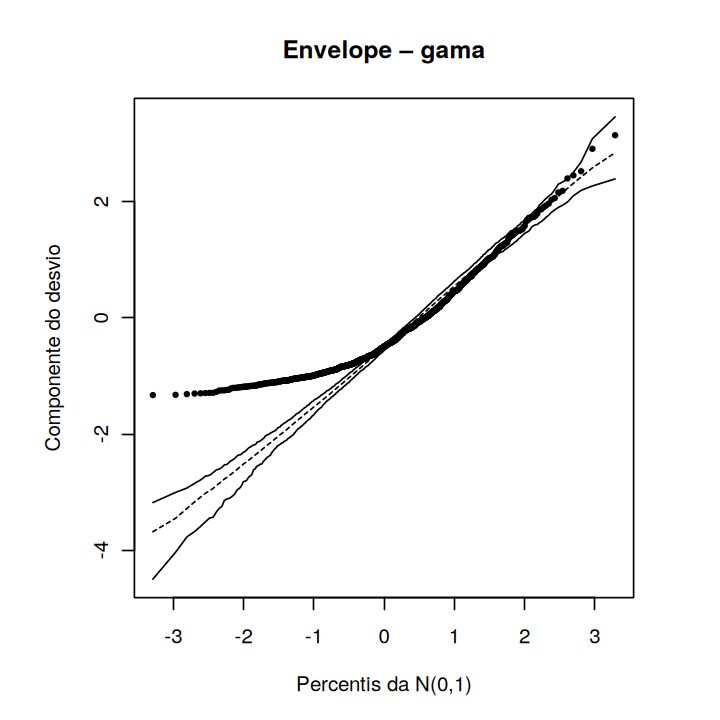

In [15]:
options(repr.plot.width = 6, repr.plot.height = 6)
set.seed(2026)                      # envelope é simulado: fixa a semente para reprodutibilidade
envelope(aj3, "Envelope – gama")

**Comentário – gama.**
- **Alavancagem:** 52 pontos ficam acima de $2p/n$, mas os valores são pequenos (máx. ≈ 0,03). Com preditores quase todos qualitativos, $h_{ii}$ alto só indica uma combinação de categorias pouco frequente. Nada preocupante.
- **Cook:** valor máximo ≈ 0,06, nenhum ponto domina o ajuste (veja a seção 8).
- **Resíduo quantílico:** assimetria = 1,18 e QQ curvado, ou seja, a cauda direita dos dados é **mais pesada** do que a gama consegue acomodar.
- **Envelope:** cerca de 65% dos pontos ficam fora das bandas, então o **modelo gama não é adequado**.
- As "retas" diagonais no canto inferior do gráfico $t_D$ × ajustado são as apólices com custo 200 (e ~354): com $y$ fixo, o resíduo vira uma função de $\hat\mu$.

## 6. Normal inversa (ligação log)

In [16]:
# Mesmo preditor do modelo gama final.
# Os coeficientes da gama servem de valores iniciais (start); sem isso o
# algoritmo da normal inversa costuma não convergir (foi o que travou a versão anterior).
aj_ni <- glm(formula(aj3), family = inverse.gaussian(link = "log"),
             start = coef(aj3), control = glm.control(maxit = 100), data = claims)
summary(aj_ni)
drop1(aj_ni, test = "F")


Call:
glm(formula = formula(aj3), family = inverse.gaussian(link = "log"), 
    data = claims, start = coef(aj3), control = glm.control(maxit = 100))

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept)   7.62881    0.15171  50.284  < 2e-16 ***
expos        -0.91086    0.19293  -4.721 2.68e-06 ***
tipov2outros  0.34399    0.16979   2.026  0.04304 *  
idadev23-4    0.17666    0.09175   1.926  0.05445 .  
areac2EF      0.34971    0.15052   2.323  0.02036 *  
idadec21-2    0.30002    0.10702   2.804  0.00515 ** 
idadec26      0.34124    0.17443   1.956  0.05070 .  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for inverse.gaussian family taken to be 0.001369389)

    Null deviance: 1.4367  on 995  degrees of freedom
Residual deviance: 1.3560  on 989  degrees of freedom
AIC: 16280

Number of Fisher Scoring iterations: 6


,Df,Deviance,AIC,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
<none>,NA,1.355988,16280.04,NA,NA
expos,1,1.389630,16302.61,24.537494,8.567601e-07
tipov2,1,1.363465,16283.50,5.453556,1.972775e-02
idadev2,1,1.360948,16281.66,3.617825,5.745388e-02
areac2,1,1.365484,16284.98,6.926228,8.626320e-03
idadec2,2,1.370075,16286.33,5.137396,6.030694e-03


**Comentário.** As estimativas têm os mesmos sinais e magnitudes parecidas com as da gama. `idadev2` fica no limite (p = 0,057). Ela foi mantida para os dois modelos terem o mesmo preditor e poderem ser comparados, e sua retirada não muda as demais conclusões.

Pontos com h > 2p/n: 78 | |t_D| > 2: 3 ( 0.3 %)
Maiores Cook:
    32    694    350    711    662 
0.0533 0.0527 0.0474 0.0329 0.0322 
Resíduo quantílico: média = -0.032  dp = 0.99  assimetria = 0.423 


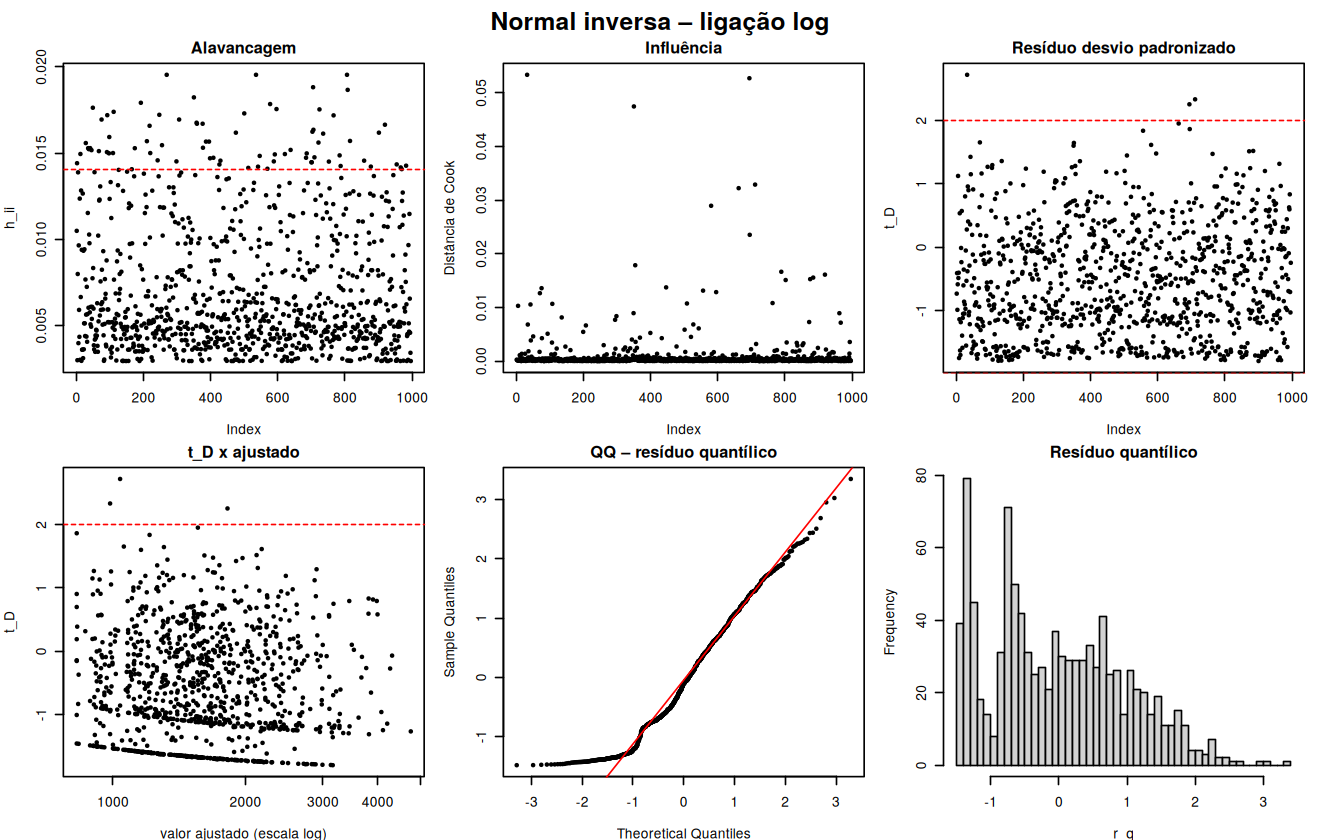

In [17]:
options(repr.plot.width = 11, repr.plot.height = 7)
dn <- diagnostico(aj_ni, "Normal inversa – ligação log")

Pontos fora do envelope: 430 de 996 ( 43.2 %)


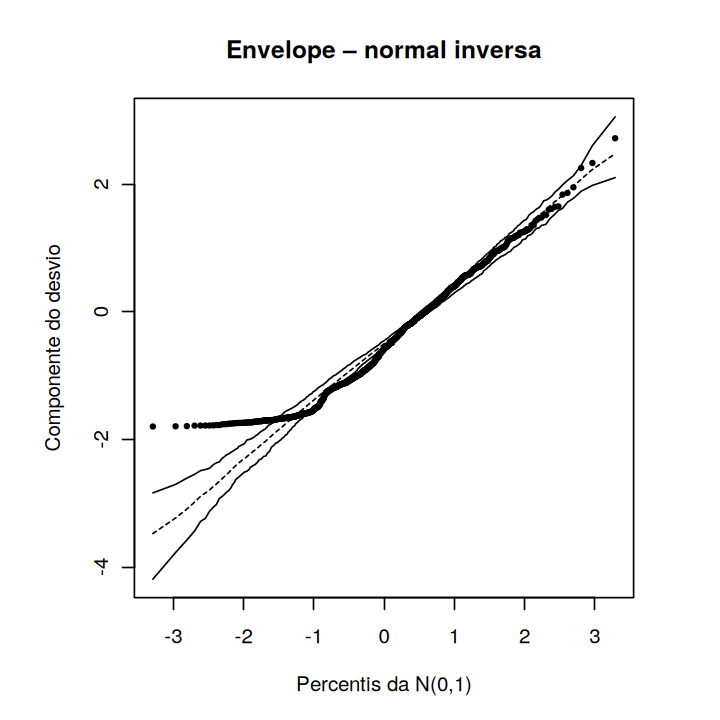

In [18]:
options(repr.plot.width = 6, repr.plot.height = 6)
set.seed(2026)
envelope(aj_ni, "Envelope – normal inversa")

**Comentário – normal inversa.** A melhora em relação à gama é grande:
- o resíduo quantílico fica próximo de N(0,1) (média −0,03, dp 0,99, assimetria 0,42), e o QQ acompanha a reta em quase toda a faixa;
- no envelope, a parte central e a cauda superior ficam dentro das bandas;
- **o único problema é a cauda inferior**: o patamar horizontal corresponde às apólices com custo 200 (o piso visto na descritiva). É uma característica dos dados, não um erro na escolha das covariáveis.

## 7. Gama x normal inversa

In [19]:
# Mesma resposta e mesmo preditor (8 parâmetros cada) -> AIC é comparável.
AIC(aj3, aj_ni)
round(cbind(gama = coef(aj3), normal_inversa = coef(aj_ni)), 3)

,df,AIC
,<dbl>,<dbl>
aj3,8,16717.50
aj_ni,8,16280.04


,gama,normal_inversa
(Intercept),7.689,7.629
expos,-1.011,-0.911
tipov2outros,0.305,0.344
idadev23-4,0.177,0.177
areac2EF,0.334,0.350
idadec21-2,0.311,0.300
idadec26,0.416,0.341


**Comentário.** O AIC da normal inversa é **437 unidades menor**, uma diferença enorme. Junto com o diagnóstico, isso indica que a **normal inversa é o modelo escolhido**. Os coeficientes dos dois modelos são muito parecidos, então as conclusões sobre as covariáveis não dependem dessa escolha.

## 8. Pontos influentes

In [20]:
# Observações com maior distância de Cook no modelo escolhido
idx <- order(dn$ci, decreasing = TRUE)[1:3]
claims[idx, c("cmsinistros", "nsin", "expos", "tipov", "idadev", "areac", "idadec")]

# Reajuste sem esses pontos e mudança relativa (%) nas estimativas
aj_ni_sem <- update(aj_ni, data = claims[-idx, ])
comp <- cbind(com = coef(aj_ni), sem = coef(aj_ni_sem),
              mudanca_pct = 100 * (coef(aj_ni_sem) - coef(aj_ni)) / abs(coef(aj_ni)))
round(comp, 3)
round(cbind(p_com = summary(aj_ni)$coef[, 4], p_sem = summary(aj_ni_sem)$coef[, 4]), 4)

,cmsinistros,nsin,expos,tipov,idadev,areac,idadec
,<dbl>,<int>,<dbl>,<fct>,<fct>,<fct>,<fct>
32,12879.66,1,0.7501711,HBACK,1,B,3
694,26507.29,1,0.4626968,STNWG,2,C,2
350,8624.63,1,0.8761123,UTE,1,A,4


,com,sem,mudanca_pct
(Intercept),7.629,7.551,-1.019
expos,-0.911,-0.906,0.550
tipov2outros,0.344,0.282,-18.135
idadev23-4,0.177,0.251,42.245
areac2EF,0.350,0.381,8.836
idadec21-2,0.300,0.297,-0.842
idadec26,0.341,0.382,11.882


,p_com,p_sem
(Intercept),0.0000,0.0000
expos,0.0000,0.0000
tipov2outros,0.0430,0.0721
idadev23-4,0.0544,0.0036
areac2EF,0.0204,0.0077
idadec21-2,0.0052,0.0030
idadec26,0.0507,0.0215


**Comentário.** As 3 observações mais influentes têm custo muito alto (12 880, 26 507 e 8 625) em perfis de custo esperado baixo. Ao retirá-las:
- `expos` e `idadec2` praticamente não mudam;
- `tipov2` cai 18% e perde significância (p = 0,07), enquanto `idadev2` fica claramente significativa (p = 0,004);
- **nenhum sinal se inverte**, ou seja, as conclusões qualitativas se mantêm. Ainda assim, vale registrar que o efeito de `tipov2` depende em parte desses pontos.

Como os pontos são valores legítimos (sinistros caros acontecem), eles **ficam no modelo**.

## 9. Interpretação do modelo final

In [22]:
# Com ligação log, exp(beta) é um efeito multiplicativo na média do custo.
# IC de 95% pela aproximação de Wald.
est <- coef(aj_ni); ep <- sqrt(diag(vcov(aj_ni)))
tab <- data.frame(exp_beta = exp(est),
                  li_95 = exp(est - 1.96 * ep), ls_95 = exp(est + 1.96 * ep),
                  efeito_pct = 100 * (exp(est) - 1))
round(tab[-1, ], 3)   # o intercepto sozinho (expos = 0) não tem interpretação prática

# Custo médio previsto para alguns perfis (expos = mediana)
perfis <- expand.grid(expos = median(claims$expos), tipov2 = levels(claims$tipov2),
                      idadev2 = "1-2", areac2 = levels(claims$areac2), idadec2 = levels(claims$idadec2))
perfis$custo_previsto <- round(predict(aj_ni, newdata = perfis, type = "response"))
perfis

,exp_beta,li_95,ls_95,efeito_pct
,<dbl>,<dbl>,<dbl>,<dbl>
expos,0.402,0.276,0.587,-59.782
tipov2outros,1.411,1.011,1.968,41.056
idadev23-4,1.193,0.997,1.428,19.323
areac2EF,1.419,1.056,1.905,41.866
idadec21-2,1.350,1.094,1.665,34.989
idadec26,1.407,0.999,1.980,40.670


expos,tipov2,idadev2,areac2,idadec2,custo_previsto
<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>
0.6160164,comum,1-2,A-D,3-5,1173
0.6160164,outros,1-2,A-D,3-5,1655
0.6160164,comum,1-2,EF,3-5,1665
0.6160164,outros,1-2,EF,3-5,2348
0.6160164,comum,1-2,A-D,1-2,1584
0.6160164,outros,1-2,A-D,1-2,2234
0.6160164,comum,1-2,EF,1-2,2247
0.6160164,outros,1-2,EF,1-2,3170
0.6160164,comum,1-2,A-D,6,1651


**Interpretação (normal inversa, ligação log).** Como $\mu = \exp(\eta)$, $e^{\beta_j}$ é o **fator multiplicativo** no custo médio por sinistro quando a covariável aumenta 1 unidade (ou muda da referência para a categoria), mantendo as demais fixas.

| Efeito | $e^{\hat\beta}$ | Leitura |
|---|---|---|
| `expos` (+0,1) | $e^{-0{,}091} = 0{,}91$ | cada 0,1 a mais de exposição reduz o custo médio em ~9% (de 0 a 1 ano: −60%). Apólices de exposição curta que tiveram sinistro tendem a ter sinistros mais caros |
| tipo `outros` vs `comum` | 1,41 (IC 1,01–1,97) | veículos menos comuns (utilitários, vans, caminhões, cupês…) têm custo médio ~41% maior |
| idade do veículo 3–4 vs 1–2 | 1,19 (IC 1,00–1,43) | veículos mais velhos: ~19% maior (efeito no limite da significância) |
| área E–F vs A–D | 1,42 (IC 1,06–1,91) | ~42% maior nas áreas E e F |
| condutor jovem (1–2) vs 3–5 | 1,35 (IC 1,09–1,67) | ~35% maior |
| condutor mais velho (6) vs 3–5 | 1,41 (IC 1,00–1,98) | ~41% maior (no limite) |

Na tabela de perfis, o custo médio previsto vai de ≈ 1 170 AUD (veículo comum, área A–D, condutor de idade intermediária) a ≈ 3 300 AUD (veículo `outros`, área E–F, condutor mais velho), uma diferença de quase 3 vezes.